In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
from matplotlib.ticker import MultipleLocator

import seaborn as sns
import os
import datetime
import pickle

from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from scipy.stats import pearsonr
from scipy.stats import entropy
from scipy import stats


from scipy.stats import ranksums, ttest_ind, ttest_rel, f_oneway, false_discovery_control, mannwhitneyu
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.model import linearreg

### Supporting functions

In [5]:
## color palette of bars in the MSE plot
colornums = sns.color_palette(palette='Blues', n_colors=6, as_cmap=False)
blues_palette_hex = list(colornums.as_hex())

### Load files

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'  # interval or not?

outsupfig_dir = 'output/circpaper_figures/supp/'

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    max_hour = df.groupby(by='Local_hour')['Episode starts with RX'].mean().idxmax()
    df['Maxalgn_hour'] = (df['Local_hour'] - max_hour)  % 24
    df['Maxalgn_mid_hour'] = ( df['Maxalgn_hour'] - 12 ) % 24
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
MIN_LS_NSAMP = 120   # 120 MAGIC for interval LS models, 0 otherwise
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']


# read the cycle charateristics csv file and store in a dictionary
lsdf_dict = {}

for patient_id in patient_list:
    
    if not os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()

In [11]:
feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [12]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [13]:
interval_start = 7   # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, verbose=True)

Dropped entries because stim AUC=0: # 9


In [14]:
### characteristics

charsdf = []

for patient_id in patient_list:
    # read dictionary
    lsdf = lsdf_dict[patient_id].copy()
    lsdf.dropna(axis=1, inplace=True)    # drop the column
    
    # get feature list
    featcols = [item for item in lsdf.columns if ('amp_unnorm' in item) or ('peakhour' in item) or ('fitpower' in item) or ('pvalue' in item)]

    # melt dataframe
    charsdf.append(lsdf.loc[lsdf['feature'].isin(subfeatdict['local']['all'])].dropna(axis=1).melt(id_vars=['npecode','feature'], 
                                                                                                   value_vars=featcols))

## convert to dataframe
charsdf = pd.concat(charsdf, axis=0, ignore_index=True)

## extract information
charsdf['charac'] = charsdf['variable'].apply(lambda x: '_'.join(x.split('_')[:-1]))
charsdf['feat_days'] = charsdf['variable'].apply(lambda x: int(x.split('_')[-1]))
charsdf['band'] = charsdf['feature'].apply(lambda x: x.split('_')[-1])

### Significance of LS models

In [15]:
## only the dataframe with pvalue information
pvaldf = charsdf.loc[(charsdf['charac']=='pvalue')].copy()
pvaldf['sig'] = pvaldf['value'].apply(lambda x: 1 if x < 0.05 else 0)   # whether pvalue is less than significance threshold

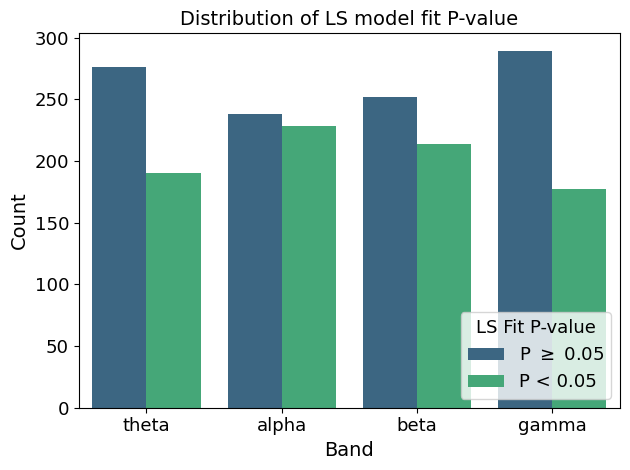

In [16]:
ax = sns.countplot(data=pvaldf, x='band', hue='sig', order=band_list, hue_order=[0,1], palette='viridis')

# format legend
moleghan, moleglab = ax.get_legend_handles_labels()
moleglab = ['P $\geq$ 0.05', 'P < 0.05']
ax.legend(moleghan, moleglab, loc='lower right', title='LS Fit P-value', 
          fontsize=13, title_fontsize=13)

plt.xlabel('Band', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Distribution of LS model fit P-value', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'lsmod_pvalue_distri_per_cycle.pdf', dpi=300)

plt.show()

### Number of significant cycles per epoch

In [17]:
## organized by 6 months information
pvaluecounts = pvaldf.groupby(by=['npecode', 'band', 'feat_days'])['sig'].sum()
pvaluecounts = pvaluecounts.reset_index()
pvaluecounts.rename(columns={'sig':'sigcycles'}, inplace=True)

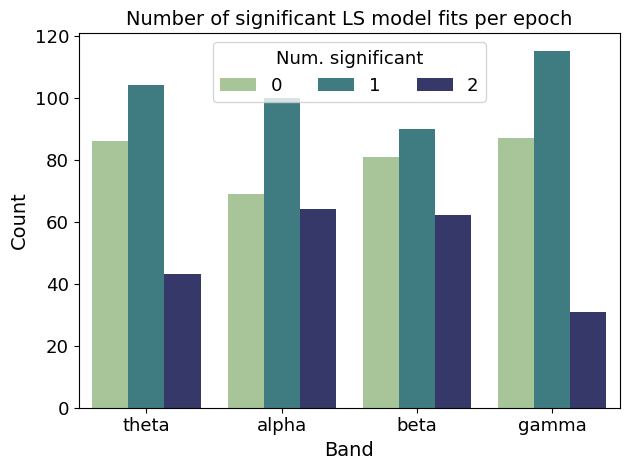

In [18]:
ax = sns.countplot(data=pvaluecounts, x='band', hue='sigcycles', order=band_list, palette='crest')

# format legend
ax.legend(loc='upper center', title='Num. significant', fontsize=13, title_fontsize=13, ncols=3)

plt.xlabel('Band', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Number of significant LS model fits per epoch', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'lsmod_num_sig_per_epoch.pdf', dpi=300)

plt.show()

### Fit power distribution

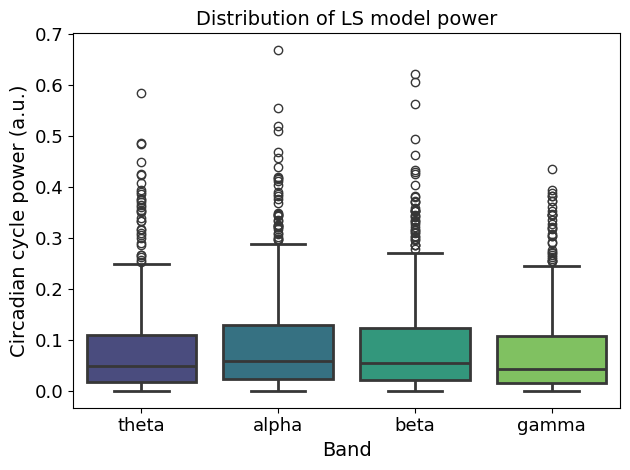

In [19]:
sns.boxplot(data=charsdf.loc[charsdf['charac']=='fitpower'], x='band', y='value', hue='band', legend=False, 
            order=band_list, palette='viridis', linewidth=2)

plt.xlabel('Band', fontsize=14)
plt.ylabel('Circadian cycle power (a.u.)', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Distribution of LS model power', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'lsmod_fitpower_boxplot.pdf', dpi=300)

plt.show()

### Amplitude distribution

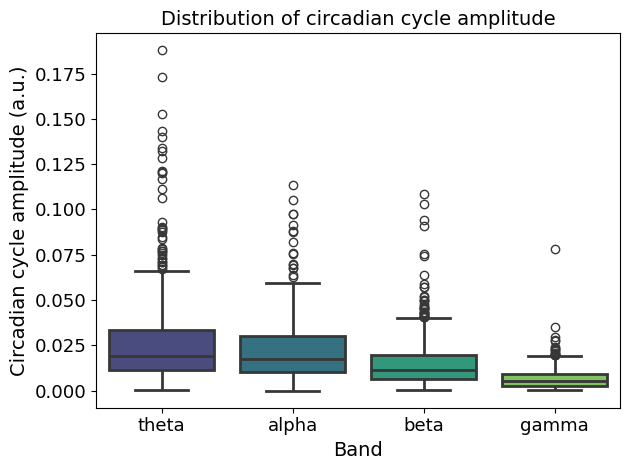

In [20]:
sns.boxplot(data=charsdf.loc[charsdf['charac']=='amp_unnorm'], x='band', y='value', hue='band', legend=False, 
            order=band_list, palette='viridis', linewidth=2)

plt.xlabel('Band', fontsize=14)
plt.ylabel('Circadian cycle amplitude (a.u.)', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Distribution of circadian cycle amplitude', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'lsmod_amplitude_boxplot.pdf', dpi=300)

plt.show()

### Distribution of peak phase

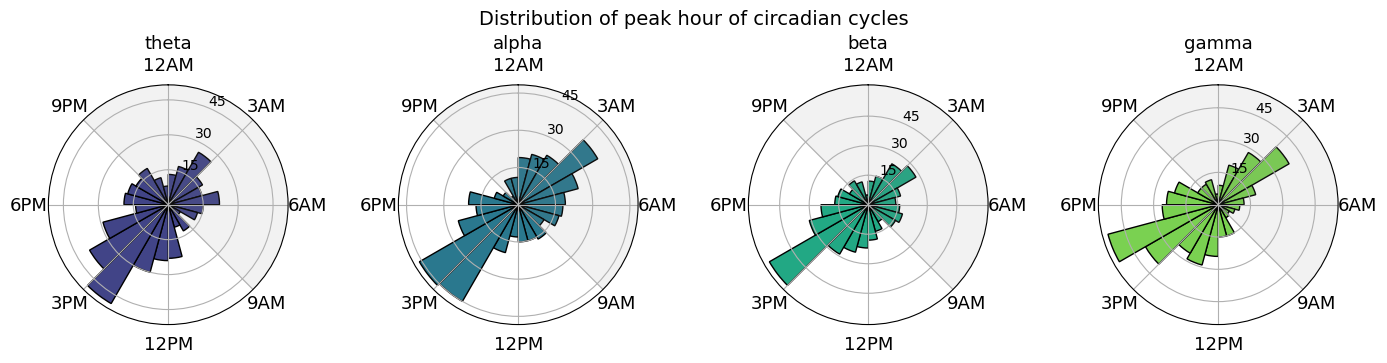

In [21]:
nrows = 1
ncols = len(band_list)

time_low, time_high = 9, 21
viridis_colors = sns.color_palette(palette='viridis', n_colors=4)

# Create polar subplot
fig, ax = plt.subplots(nrows, ncols, figsize=(3.5*ncols, 3.5*nrows), subplot_kw={'projection': 'polar'}, layout='constrained')

for ii in range(len(ax)):
    # data of given band
    cycle_peak_hours = charsdf.loc[(charsdf['charac']=='peakhour') & (charsdf['band']==band_list[ii])]['value'].values
        
    # Create histogram
    ax[ii].hist(np.pi/12 * cycle_peak_hours, bins=np.linspace(0, 2*np.pi, 25), 
                color=viridis_colors[ii], edgecolor='k', alpha=1.0)
    
    ax[ii].axvspan(xmin=(time_high-24) * np.pi/12, xmax=time_low * np.pi/12, color='grey', alpha=0.1)
    
    # Customize plot
    ax[ii].set_theta_zero_location("N")  # Set 0 at the top
    ax[ii].set_theta_direction(-1)      # Clockwise direction
    ax[ii].set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4, 
                         np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4], 
                  labels=['12AM', '3AM', '6AM', '9AM', 
                          '12PM', '3PM', '6PM', '9PM'], fontsize=13)
    ax[ii].set_yticks(ticks=[15, 30, 45])

    # asethetics
    ax[ii].set_title(band_list[ii], fontsize=13)

fig.suptitle('Distribution of peak hour of circadian cycles', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'lsmod_cc_peak_dist_all_bands.pdf', dpi=300)

plt.show()